## 1. Imports ##

In [25]:
# Core
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt

# Splitting / validation
from sklearn.model_selection import train_test_split

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Models
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Metrics
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# Optional: set a global random seed (do not remove)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# 2. Data Loading and EDA #

In [26]:
df = pl.read_csv("financial_fraud_detection_dataset.csv")
print("Shape: ", df.shape)
display(df.head())

Shape:  (5000000, 18)


transaction_id,timestamp,sender_account,receiver_account,amount,transaction_type,merchant_category,location,device_used,is_fraud,fraud_type,time_since_last_transaction,spending_deviation_score,velocity_score,geo_anomaly_score,payment_channel,ip_address,device_hash
str,str,str,str,f64,str,str,str,str,bool,str,str,f64,i64,f64,str,str,str
"""T100000""","""2023-08-22T09:22:43.516168""","""ACC877572""","""ACC388389""",343.78,"""withdrawal""","""utilities""","""Tokyo""","""mobile""",false,null,null,-0.21,3,0.22,"""card""","""13.101.214.112""","""D8536477"""
"""T100001""","""2023-08-04T01:58:02.606711""","""ACC895667""","""ACC944962""",419.65,"""withdrawal""","""online""","""Toronto""","""atm""",false,null,null,-0.14,7,0.96,"""ACH""","""172.52.47.194""","""D2622631"""
"""T100002""","""2023-05-12T11:39:33.742963""","""ACC733052""","""ACC377370""",2773.86,"""deposit""","""other""","""London""","""pos""",false,null,null,-1.78,20,0.89,"""card""","""185.98.35.23""","""D4823498"""
"""T100003""","""2023-10-10T06:04:43.195112""","""ACC996865""","""ACC344098""",1666.22,"""deposit""","""online""","""Sydney""","""pos""",false,null,null,-0.6,6,0.37,"""wire_transfer""","""107.136.36.87""","""D9961380"""
"""T100004""","""2023-09-24T08:09:02.700162""","""ACC584714""","""ACC497887""",24.43,"""transfer""","""utilities""","""Toronto""","""mobile""",false,null,null,0.79,13,0.27,"""ACH""","""108.161.108.255""","""D7637601"""


## Target Class Balance Inspection ##

In [27]:
# fraud class balance
fraud_count = df["is_fraud"].value_counts()
display(fraud_count)
fraud_pct = df["is_fraud"].value_counts(normalize=True)*100
display(fraud_pct)

is_fraud,count
bool,u32
false,4820447
true,179553


is_fraud,proportion
f64,f64
0.0,96.40894
100.0,3.59106


## Null Inspection ##

In [28]:
null_counts = df.null_count()
display(null_counts)

transaction_id,timestamp,sender_account,receiver_account,amount,transaction_type,merchant_category,location,device_used,is_fraud,fraud_type,time_since_last_transaction,spending_deviation_score,velocity_score,geo_anomaly_score,payment_channel,ip_address,device_hash
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,4820447,896513,0,0,0,0,0,0


Only two features with null values are `fraud_type` and `time_since_last_transaction`. fraud_type is an indirect identifier so it will very likely be removed. 

## Temporal Feature Inspection ##
The split will have to take into account that the data is temporal. The two features analysed below are `timestamp` and `time_since_last_transaction`

In [29]:
# look at timestamp values
display(df.select("timestamp").head(10))
# count distinct values to understand the column better
print("n_unique timestamp:", df.select(pl.col("timestamp").n_unique()).item())

# look at non-null time_since_last_transaction values (we saw above that a lot were null)
display(df.filter(pl.col("time_since_last_transaction").is_not_null()).select("time_since_last_transaction").head(20))
print("n_unique time_since_last_transaction:", df.select(pl.col("time_since_last_transaction").n_unique()).item())

timestamp
str
"""2023-08-22T09:22:43.516168"""
"""2023-08-04T01:58:02.606711"""
"""2023-05-12T11:39:33.742963"""
"""2023-10-10T06:04:43.195112"""
"""2023-09-24T08:09:02.700162"""
"""2023-11-20T17:49:27.940971"""
"""2023-11-11T11:15:41.359248"""
"""2023-06-09T06:32:36.945101"""
"""2023-02-11T06:57:40.585720"""


n_unique timestamp: 4999998


time_since_last_transaction
str
"""-4797.552867613611"""
"""3705.7383483549997"""
"""2158.9064329361113"""
"""-71.3938477925"""
"""1400.4134824294445"""
…
"""-1338.5501861188889"""
"""4646.0275480825"""
"""-2391.075178002222"""


n_unique time_since_last_transaction: 4103488


**Note on `time_since_last_transaction`**

According to the dataset description, this feature represents the number of hours since the user's previous transaction. However, inspection reveals that the column contains both positive and negative values.

Since a true elapsed time cannot be negative, this may be because the dataset was synthetically generated.

Despite this inconsistency, the feature will probably be retained as a numeric predictor because it may still capture the fraudulent behavioral patterns that were incorporated when the dataset was generated

## Categorical Feature Inspection ##

In [30]:
categorical_cols = [col for col,dtype in df.schema.items() if dtype == pl.String]

print("\nUnique value counts:")
for col in categorical_cols:
    n_unique = df.select(pl.col(col).n_unique()).item()
    print(f"{col}: {n_unique}")


Unique value counts:
transaction_id: 5000000
timestamp: 4999998
sender_account: 896513
receiver_account: 896639
transaction_type: 4
merchant_category: 8
location: 8
device_used: 4
fraud_type: 2
time_since_last_transaction: 4103488
payment_channel: 4
ip_address: 4997068
device_hash: 3835723


**Categorical Feature Cardinality**

Examined all string-based columns and counted the number of unique values in each feature. This helps determine how each variable should be treated during preprocessing.

Several columns exhibit extremely high cardinality, including `transaction_id`, `timestamp`, `ip_address`, and `device_hash`. These behave more like identifiers rather than meaningful categorical variables. Including them directly in a machine learning model could lead to severe overfitting and poor generalization. These columns will therefore be excluded from modeling.

The `sender_account` and `receiver_account` columns also contain a very large number of unique values (approximately 900,000 each). These represent individual user accounts. While potentially informative, they are too high-cardinality for standard encoding methods and will be excluded for this project.

Several columns contain a small number of distinct categories, including `transaction_type`, `merchant_category`, `location`, `device_used`, and `payment_channel`. These are appropriate candidates for categorical encoding during preprocessing.

Finally, the `fraud_type` column appears to be directly related to the target variable `is_fraud`, since it only exists for fraudulent transactions. Including this feature would introduce target leakage, so it will also be removed before modeling.

## Numerical Feature Inspection ##
The numeric features are inspected using descriptive statistics and histograms to better understand their distributions and potential preprocessing needs.

statistic,amount,spending_deviation_score,velocity_score,geo_anomaly_score
str,f64,f64,f64,f64
"""count""",5e6,5e6,5e6,5e6
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",358.934269,-0.000388,10.50132,0.500029
"""std""",469.933311,1.000807,5.766842,0.288635
"""min""",0.01,-5.26,1.0,0.0
"""25%""",26.57,-0.68,5.0,0.25
"""50%""",138.67,-0.0,11.0,0.5
"""75%""",503.89,0.67,16.0,0.75
"""max""",3520.57,5.02,20.0,1.0


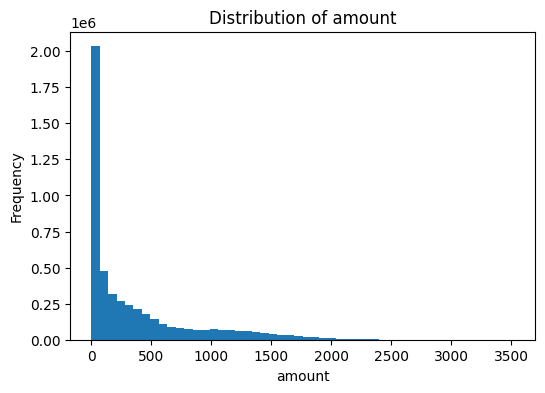

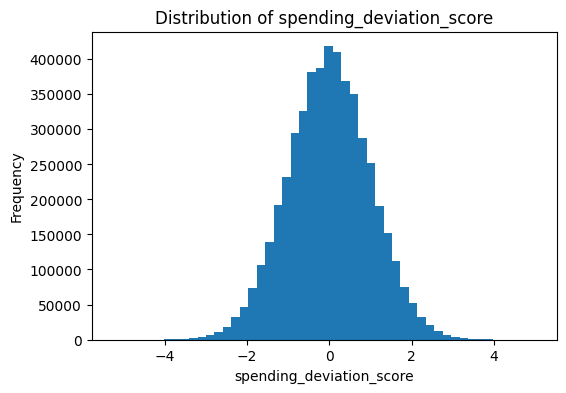

In [ ]:
numeric_cols = [col for col,dtype in df.schema.items()
if dtype in [pl.Int64, pl.Float64]
]

display(df.select(numeric_cols).describe())

for col in numeric_cols:
    plt_data = df.select(col).drop_nulls().to_series().to_list()
    plt.figure(figsize=(6,4))
    plt.hist(plt_data, bins=50)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

**Amount**

The transaction `amount` feature shows a strongly **right-skewed distribution**, with many small transactions and a long tail of larger values up to approximately \$3500. This pattern is typical for financial transaction data. While tree-based models such as Random Forest and XGBoost are generally robust to skewed distributions, the feature may still benefit from transformation or scaling depending on the model used.

**Spending Deviation Score**

The `spending_deviation_score` appears to follow a roughly **normal distribution centered near zero**, suggesting it may represent a standardized behavioral anomaly metric. Because this feature is already centered and symmetric, no major transformation appears necessary.

**Velocity Score**

The `velocity_score` variable appears to take **discrete integer values ranging from 1 to 20**, with relatively uniform frequency across values. This suggests it may represent a derived behavioral score rather than a continuous measurement.

**Geo Anomaly Score**

The `geo_anomaly_score` ranges from **0 to 1**, indicating it may represent a normalized anomaly metric related to geographic transaction behavior. The distribution appears fairly spread across the range.

Overall, the numeric features appear well-structured and suitable for modeling. No extreme anomalies or invalid values were detected during this inspection.

# 3. Data Cleaning & Feature Decisions #

## Parsing & Type Conversions ##

In [ ]:
df_clean = df.with_columns([
    pl.col("timestamp").str.strptime(pl.Datetime, strict=False).alias("timestamp"),
    pl.col("time_since_last_transaction").cast(pl.Float64).alias("time_since_last_transaction")
])

display(df_clean.schema)

The `timestamp` column was parsed from string format into a proper datetime type to allow chronological sorting of the dataset. This is necessary for performing a time-based train/validation/test split later in the pipeline.

Additionally, the `time_since_last_transaction` column was converted to a floating-point numeric type to ensure it can be treated as a quantitative feature during modeling.

## Removing Unused/Problematic Features ##
Several columns were removed from the modeling dataset because they were either identifiers, sources of target leakage, or extremely high-cardinality variables that are not suitable for direct use in the baseline fraud detection model.

In [ ]:
cols_to_drop = [
    "transaction_id",      # unique identifier
    "fraud_type",          # leakage (derived from is_fraud)
    "sender_account",      # extremely high cardinality
    "receiver_account",    # extremely high cardinality
    "ip_address",          # high cardinality identifier
    "device_hash"          # high cardinality identifier
]

df_clean = df_clean.drop(cols_to_drop)

print("Remaining columns:")
display(df_clean.columns)



- `transaction_id` was removed because it is a unique identifier for each transaction. It does not contain generalizable behavioral information and would not be useful as a predictive feature.
- `fraud_type` was removed because it would introduce **target leakage** in the binary fraud detection task. Since this column is only defined for fraudulent transactions, the model could use it to indirectly infer the target variable `is_fraud`.
- `sender_account` and `receiver_account` were removed because they contain extremely large numbers of unique values and behave like account identifiers rather than standard categorical variables. Encoding them directly would produce a very large feature space and likely lead to overfitting.
- `ip_address` was removed because it behaves like a near-unique identifier with extremely high cardinality. Including raw IP addresses directly would not generalize well and would substantially increase model complexity.
- `device_hash` was removed for the same reason: it is a high-cardinality identifier-like feature.Including it directly would add complexity without providing a reliable, generalizable signal for the baseline model.

These removals help ensure that the baseline model focuses on features that are interpretable, generalizable, and appropriate for structured machine learning.

**Type conversion before splitting**

Before performing the chronological split, the relevant columns were converted to appropriate data types.

- `timestamp` was converted from string to `Datetime` so that the dataset can be sorted and split in true chronological order.
- `time_since_last_transaction` was converted from string to `Float64` so it can be treated as a numeric feature during preprocessing and modeling.

This step prepares the dataset for time-aware splitting and later feature engineering.

In [ ]:
df_clean = df_clean.sort("timestamp")

display(
    df_clean.select([
        pl.col("timestamp").min().alias("min_timestamp"),
        pl.col("timestamp").max().alias("max_timestamp")
    ])
)

display(df_clean.head())

## Feature Grouping ##
After removing identifier-like and leakage-prone columns, the remaining features were grouped according to their data type so that appropriate preprocessing steps can be applied later in the pipeline.

In [ ]:
target_col = "is_fraud"
time_col = "timestamp"

numeric_features = [
    col for col, dtype in df_clean.schema.items()
    if dtype in [pl.Float64, pl.Int64] and col != target_col
]

categorical_features = [
    col for col, dtype in df_clean.schema.items()
    if dtype == pl.String
]

display("Numeric features:", numeric_features)
display("Categorical features:", categorical_features)

**Numeric Features**

- `amount`
- `time_since_last_transaction`
- `spending_deviation_score`
- `velocity_score`
- `geo_anomaly_score`

These features represent quantitative measurements describing transaction behavior and anomaly indicators. They will be handled using numeric preprocessing steps.

**Categorical Features**

- `transaction_type`
- `merchant_category`
- `location`
- `device_used`
- `payment_channel`

These variables describe contextual information about the transaction. Since machine learning models require numeric inputs, these categorical variables will later be converted to numerical form using **one-hot encoding**.

# 4. Train / Validation / Test Split #
Because the dataset contains timestamped transaction data, the dataset was split **chronologically** rather than randomly. This ensures that the model is always trained on past transactions and evaluated on future transactions, which more accurately reflects real-world fraud detection scenarios.

In [ ]:
# sort chronologically first
df_clean = df_clean.sort("timestamp")

# dataset size
n = df_clean.height

# split indices
train_end = int(n * 0.60)
val_end = int(n * 0.80)

# chronological splits
train_df = df_clean.slice(0, train_end)
val_df = df_clean.slice(train_end, val_end - train_end)
test_df = df_clean.slice(val_end, n - val_end)

# separate features and target
X_train = train_df.drop("is_fraud", "timestamp")
y_train = train_df.select("is_fraud")

X_val = val_df.drop("is_fraud", "timestamp")
y_val = val_df.select("is_fraud")

X_test = test_df.drop("is_fraud", "timestamp")
y_test = test_df.select("is_fraud")

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

split_summary = pl.DataFrame({
    "split": ["train", "validation", "test"],
    "n_rows": [train_df.height, val_df.height, test_df.height],
    "min_timestamp": [
        train_df.select(pl.min("timestamp")).item(),
        val_df.select(pl.min("timestamp")).item(),
        test_df.select(pl.min("timestamp")).item()
    ],
    "max_timestamp": [
        train_df.select(pl.max("timestamp")).item(),
        val_df.select(pl.max("timestamp")).item(),
        test_df.select(pl.max("timestamp")).item()
    ],
    "fraud_rate": [
        y_train.select(pl.col("is_fraud").mean()).item(),
        y_val.select(pl.col("is_fraud").mean()).item(),
        y_test.select(pl.col("is_fraud").mean()).item()
    ]
})

display(split_summary)


The dataset was sorted by `timestamp` and divided into:
- **Training set:** 60% of the earliest transactions
- **Validation set:** the next 20% of transactions
- **Test set:** the most recent 20% of transactions

The min_timestamp and max_timestamp of each split verfies there is no temporal overlap. The fraud rate remains  similar across all splits (~3.6%), indicating that the split did not introduce significant class imbalance differences between the datasets.

# Preprocessing Pipeline #

## Convert from polars to pandas ##
Now that data is clean and in smaller chunks, we can move to pandas from polars so wer can use sklearn

In [ ]:

X_train = X_train.to_pandas()
X_val = X_val.to_pandas()
X_test = X_test.to_pandas()

y_train = y_train.to_pandas().squeeze()
y_val = y_val.to_pandas().squeeze()
y_test = y_test.to_pandas().squeeze()

# 5. Baseline Model #

For the baseline, I used **Logistic Regression** because it is a simple and common starting model for binary classification. It is easier to explain than an ensemble model and makes a better reference point before trying more advanced models later.

The dataset is also highly imbalanced, so I used `class_weight="balanced"` to help the model pay more attention to the fraud class. This does not guarantee strong performance, but it gives a fairer first benchmark than predicting only the majority class.

This baseline is meant to answer one main question: **can a simple model separate fraud from non-fraud at all using the current features?**


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

RANDOM_STATE = 42

# auto-detect features
numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X_train.select_dtypes(include=["object"]).columns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

# train
baseline_model.fit(X_train, y_train)

# --- Validation Set ---
y_val_pred = baseline_model.predict(X_val)
y_val_proba = baseline_model.predict_proba(X_val)[:, 1]

print("Baseline Model — Validation Set")
print("Accuracy:         ", round(accuracy_score(y_val, y_val_pred), 4))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_val, y_val_pred), 4))
print("Precision:        ", round(precision_score(y_val, y_val_pred, zero_division=0), 4))
print("Recall:           ", round(recall_score(y_val, y_val_pred, zero_division=0), 4))
print("F1:               ", round(f1_score(y_val, y_val_pred, zero_division=0), 4))
print("ROC-AUC:          ", round(roc_auc_score(y_val, y_val_proba), 4))

cm_val = confusion_matrix(y_val, y_val_pred)
ConfusionMatrixDisplay(cm_val, display_labels=["Not Fraud", "Fraud"]).plot(cmap="Blues")
plt.title("Baseline Confusion Matrix — Validation Set")
plt.show()

# --- Test Set ---
y_test_pred = baseline_model.predict(X_test)
y_test_proba = baseline_model.predict_proba(X_test)[:, 1]

print("\nBaseline Model — Test Set")
print("Accuracy:         ", round(accuracy_score(y_test, y_test_pred), 4))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_test, y_test_pred), 4))
print("Precision:        ", round(precision_score(y_test, y_test_pred, zero_division=0), 4))
print("Recall:           ", round(recall_score(y_test, y_test_pred, zero_division=0), 4))
print("F1:               ", round(f1_score(y_test, y_test_pred, zero_division=0), 4))
print("ROC-AUC:          ", round(roc_auc_score(y_test, y_test_proba), 4))

cm_test = confusion_matrix(y_test, y_test_pred)
ConfusionMatrixDisplay(cm_test, display_labels=["Not Fraud", "Fraud"]).plot(cmap="Blues")
plt.title("Baseline Confusion Matrix — Test Set")
plt.show()


The baseline results should be read carefully because the dataset is imbalanced.

- **Accuracy** can look high even when the model misses many fraud cases, so it is not the best metric on its own.
- **Balanced accuracy** is more useful here because it gives equal importance to both classes.
- **Precision** shows how many predicted fraud cases were actually fraud.
- **Recall** shows how many real fraud cases were successfully found.
- **F1-score** helps balance precision and recall.
- **ROC-AUC** is useful for checking how well the model separates the two classes overall.

Since this is a baseline, the goal is not to get the best score right away. The goal is to create a simple reference point so later models can be compared against it in a fair way.


# 6. Model Training, Hyperparameter Tuning, and Evaluation #

After building the baseline model, I trained two stronger models: a **Decision Tree** and a **Random Forest**.

To keep this section aligned with the lab workflow, I used:
- the **training set** to fit the models,
- **GridSearchCV** for hyperparameter tuning,
- and the **validation set** to compare performance.

I kept the parameter grids small on purpose so the notebook stays practical to run like a normal student lab notebook. I used **ROC-AUC** as the main scoring metric because the fraud dataset is imbalanced, so accuracy alone is not enough.


In [ ]:
from sklearn.model_selection import GridSearchCV

def evaluate_model(name, model, X_eval, y_eval):
    y_pred = model.predict(X_eval)
    y_proba = model.predict_proba(X_eval)[:, 1]

    results = {
        "Model": name,
        "Accuracy": round(accuracy_score(y_eval, y_pred), 4),
        "Balanced Accuracy": round(balanced_accuracy_score(y_eval, y_pred), 4),
        "Precision": round(precision_score(y_eval, y_pred, zero_division=0), 4),
        "Recall": round(recall_score(y_eval, y_pred, zero_division=0), 4),
        "F1": round(f1_score(y_eval, y_pred, zero_division=0), 4),
        "ROC-AUC": round(roc_auc_score(y_eval, y_proba), 4)
    }

    return results, y_pred

model_results = []

## Tuned Decision Tree ##

A Decision Tree is more flexible than Logistic Regression because it can model non-linear patterns and feature interactions.  
I tuned a few tree size and class-balance settings to see whether it could detect fraud better than the baseline.

In [ ]:
dt_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE))
])

# small grid so it stays fast and still follows the lab style
dt_param_grid = {
    "classifier__max_depth": [5, 10],
    "classifier__min_samples_split": [2, 10],
    "classifier__class_weight": [None, "balanced"]
}

dt_grid = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=dt_param_grid,
    scoring="roc_auc",
    cv=3,
    n_jobs=-1,
    verbose=1
)

dt_grid.fit(X_train, y_train)

print("Best Decision Tree Parameters:")
print(dt_grid.best_params_)
print("Best Decision Tree CV ROC-AUC:", round(dt_grid.best_score_, 4))

best_dt = dt_grid.best_estimator_
dt_results, y_val_pred_dt = evaluate_model("Decision Tree", best_dt, X_val, y_val)
model_results.append(dt_results)

print("\nDecision Tree - Validation Set")
for metric, value in dt_results.items():
    if metric != "Model":
        print(f"{metric}: {value}")

cm_dt = confusion_matrix(y_val, y_val_pred_dt)
ConfusionMatrixDisplay(cm_dt, display_labels=["Not Fraud", "Fraud"]).plot(cmap="Blues")
plt.title("Decision Tree Confusion Matrix - Validation Set")
plt.show()


## Tuned Random Forest ##

A Random Forest is an ensemble of many decision trees. It is usually stronger than a single tree because it reduces overfitting and can handle more complex patterns.  
I tuned a small grid of settings so the notebook still stays practical and consistent with a student lab workflow.

In [ ]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

# smaller grid to keep runtime reasonable on a large dataset
rf_param_grid = {
    "classifier__n_estimators": [100],
    "classifier__max_depth": [10, 20],
    "classifier__class_weight": ["balanced", "balanced_subsample"]
}

rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    scoring="roc_auc",
    cv=3,
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest Parameters:")
print(rf_grid.best_params_)
print("Best Random Forest CV ROC-AUC:", round(rf_grid.best_score_, 4))

best_rf = rf_grid.best_estimator_
rf_results, y_val_pred_rf = evaluate_model("Random Forest", best_rf, X_val, y_val)
model_results.append(rf_results)

print("\nRandom Forest - Validation Set")
for metric, value in rf_results.items():
    if metric != "Model":
        print(f"{metric}: {value}")

cm_rf = confusion_matrix(y_val, y_val_pred_rf)
ConfusionMatrixDisplay(cm_rf, display_labels=["Not Fraud", "Fraud"]).plot(cmap="Blues")
plt.title("Random Forest Confusion Matrix - Validation Set")
plt.show()


## Validation Comparison ##

The table below compares the tuned models on the **validation set**.  
This comparison will be used in the next section to choose the best model before threshold tuning.

In [ ]:
results_df = pd.DataFrame(model_results)
results_df = results_df.sort_values(by="ROC-AUC", ascending=False).reset_index(drop=True)
display(results_df)

From this section, the main thing I will look at is **ROC-AUC**, along with **recall** and **F1-score**, because fraud detection is an imbalanced classification problem.  
The best-performing validation model will be selected in the next step for threshold tuning.